# Exploratory data analysis: TxDOT CRIS crashes, Lubbock District, 2020–2026

**Goal.** Understand `district_crashes.csv` well enough to compute three things correctly:
crash counts by KABCO severity, the top contributing factors, and crash patterns over time.
The EDA stays on the columns those metrics, the API filters and the map need.

**How to read this notebook.** Each section states a question, answers it with code, and ends
with the decision it leads to. Every decision is implemented once, in `roadalyx/cris.py`, and
section 6 runs that code so the numbers here and in the API are the same numbers.

| | |
|---|---|
| Source | TxDOT Crash Records Information System (CRIS), query export provided by TransTech Lab |
| Scope | TxDOT Lubbock District, crash years 2020–2026, severities K, A, B, C |
| Raw file | `data/raw/district_crashes.csv` (not committed, see `data/raw/README.md`) |

## 1. Reading the file

The file does not start with the header row. Look at the first lines before parsing anything.

In [1]:
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw/district_crashes.csv")

# Print the first 12 lines, cut to 110 characters, to see where the table really starts.
with RAW.open(encoding="utf-8-sig") as f:          # utf-8-sig drops the byte-order mark (BOM)
    for i, line in zip(range(12), f):
        print(f"{i:2d} | {line.rstrip()[:110]}")

 0 | "All crash data available using this tool represents reportable data collected from Texas Peace Officer's Cras
 1 | 
 2 | "Query Result Counts:"
 3 | "Your query returned a total of 24,261 Crashes containing 48,043 Units and 67,906 Persons"
 4 | 
 5 | "Filters Applied to current Query:"
 6 | "Crash Year Is In  2020 or 2021 or 2022 or 2023 or 2024 or 2025 or 2026"
 7 | "TxDOT District Is Equal To LUBBOCK"
 8 | "Crash Severity Is In A - SUSPECTED SERIOUS INJURY or B - SUSPECTED MINOR INJURY or K - FATAL INJURY or C - PO
 9 | 
10 | 
11 | "Crash ID","Active School Zone Flag","Adjusted Average Daily Traffic Amount","Adjusted Percentage of Average D


Lines 0–10 are a disclaimer, the query's result counts and its filters. The header is line 11.
Line 3 is useful later: **24,261 crashes, 48,043 units (vehicles), 67,906 persons**. A correct
cleaning must find exactly 24,261 crashes.

`roadalyx.cris.read_export` finds the header by its first cell (`"Crash ID"`) instead of
hard-coding 11 lines, so another CRIS export with a longer filter list still parses.

In [2]:
# Read every cell as text and keep "No Data" as text: we decide what counts as missing, not pandas.
persons = pd.read_csv(RAW, skiprows=11, encoding="utf-8-sig", dtype=str, keep_default_na=False)
print(persons.shape)
persons.iloc[:3, :8]

(67906, 94)


## 2. What is one row?

67,906 rows for 24,261 declared crashes: a row is not a crash.

In [3]:
rows_per_crash = persons.groupby("Crash ID").size()
print("distinct Crash IDs:", rows_per_crash.size)
rows_per_crash.value_counts().sort_index().head(10).rename("crashes").to_frame().T

distinct Crash IDs: 24261


,1,2,3,4,5,6,7,8,9,10
crashes,4136,8757,5495,2856,1550,746,365,168,90,35


In [4]:
# One crash, four rows: same crash fields, different people.
cols = ["Crash ID", "Crash Date", "County", "Crash Severity", "Person Type", "Person Age", "Person Injury Severity"]
persons.loc[persons["Crash ID"] == "17495023", cols]

**One row = one person involved in a crash.** Crash 17495023 has two drivers and two
passengers; the crash fields repeat on all four rows. Counting rows would count this crash
four times, and the whole file 67,906 times instead of 24,261.

Before keeping one row per crash, check that the repeated fields really are identical inside
every crash. If they were not, "keep the first row" would silently pick one version.

In [5]:
# For every column: in how many crashes do the person rows disagree?
varying = persons.groupby("Crash ID").nunique()
disagree = (varying > 1).sum()
crash_level = disagree[disagree == 0].index.tolist()
print(len(crash_level), "columns never vary inside a crash (crash level)")
disagree[disagree > 0].sort_values(ascending=False).rename("crashes where rows differ").to_frame()

66 columns never vary inside a crash (crash level)


,crashes where rows differ
Person Age,19759
Vehicle Model Name,18346
Contributing Factor 1,17996
Person Injury Severity,17757
Vehicle Model Year,17669
Vehicle Make,17169
Person Total Injury Count,16369
Vehicle Color,15986
Driver Zip Code,15791
Person Gender,13896


66 columns are constant inside every crash; the 27 that vary are person or vehicle
attributes (age, injury, vehicle make, unit-level contributing factors).

**Decision 1.** Build a crash table with one row per Crash ID from the crash-level columns.
Nothing is deleted from the source; the crash table is a second, derived table.

Two more checks before trusting the crash table:

In [6]:
crashes = persons.drop_duplicates("Crash ID").copy()
print("crashes:", len(crashes), "| matches the header's 24,261:", len(crashes) == 24_261)

# Crash severity should equal the worst injury among the crash's persons (KABCO convention).
rank = {"K": 4, "A": 3, "B": 2, "C": 1, "N": 0, "9": 0}          # "99 - UNKNOWN" ranks lowest
worst = persons["Person Injury Severity"].str[0].map(rank).groupby(persons["Crash ID"]).max()
crash_sev = crashes.set_index("Crash ID")["Crash Severity"].str[0].map(rank)
print("crashes whose severity is not their worst injury:", int((worst.reindex(crash_sev.index) != crash_sev).sum()))

# K crashes and only K crashes should report deaths.
k = crashes["Crash Severity"].str.startswith("K")
dead = crashes["Crash Death Count"].astype(int) > 0
print("K without a death:", int((k & ~dead).sum()), "| death without K:", int((~k & dead).sum()))

# 295 person rows are exact duplicates of another row of the same crash.
print("fully identical person rows:", int(persons.duplicated().sum()))

crashes: 24261 | matches the header's 24,261: True
crashes whose severity is not their worst injury: 0
K without a death: 0 | death without K: 0


fully identical person rows: 295


Both checks pass: the crash table is internally consistent. The 295 identical person rows
cannot be told apart from two passengers with the same age, sex and injury (the export has no
person ID), so they are left alone. They do not affect any crash-level metric.

## 3. Columns kept, and why

From the 66 crash-level columns, the pipeline keeps the ones a metric, a filter or the map uses.

| Column | Used for |
|---|---|
| Crash ID | key; one record per crash |
| Crash Severity | metric 1 (KABCO counts); `severity` filter |
| Contributing Factors | metric 2 (top factors); `factor` filter |
| Crash Date, Crash Time | metric 3 (year, month, hour, weekday) |
| County | `county` filter, county comparison |
| Road Class | `road_class` filter; severity by road type |
| Latitude, Longitude | crash map |
| Crash Death Count, Crash Suspected Serious Injury Count, Crash Total Injury Count | people killed or injured, not only crashes |
| Speed Limit, Rural Flag, Intersection Related, At Intersection Flag, Weather Condition, Manner of Collision, First Harmful Event, Street Name, Construction Zone Flag, Active School Zone Flag, TxDOT Reportable Flag | context an analyst filters or reads on a crash record |
| Person Type (person level) | whether a pedestrian, pedalcyclist or motorcyclist was involved |

Left out on purpose: roadway inventory fields (AADT, lane and shoulder widths, roadbed width),
44 % "No Data" because they only exist on TxDOT on-system roads; and four columns that are
100 % "No Data" (Surface Type, Feature Crossed by Bridge, two HOV / clearance fields).
Person and vehicle details (age, ethnicity, vehicle make) are not needed for crash metrics and
are personal data, so they never leave the raw file.

## 4. Data quality issues

### 4.1 Missing values are written as text

In [7]:
kept = ["Contributing Factors", "Road Class", "Speed Limit", "Latitude", "Longitude", "Weather Condition",
        "Street Name", "Intersection Related", "Manner of Collision", "County", "Crash Time"]
sentinels = ["No Data", "NO DATA", "NOT REPORTED", ""]
pd.DataFrame({s or "(empty)": crashes[kept].eq(s).sum() for s in sentinels})

,No Data,NO DATA,NOT REPORTED,(empty)
Contributing Factors,0,0,0,0
Road Class,0,0,0,0
Speed Limit,0,0,0,0
Latitude,849,0,0,0
Longitude,849,0,0,0
Weather Condition,0,0,0,0
Street Name,0,0,0,0
Intersection Related,0,0,0,0
Manner of Collision,0,0,0,0
County,0,0,0,0


Only Latitude/Longitude carry "No Data" among the kept columns (849 crashes, 3.5 %), plus
"NO DATA" in Street Number and "NOT REPORTED" in Intersecting Street Name, which are not kept.

**Decision 2.** Treat `""`, `NO DATA` and `NOT REPORTED` (any case) as missing. Crashes without
coordinates stay in every count; they are only absent from the map, and the API reports how many.

### 4.2 Coordinates, speed limits, times

In [8]:
lat = pd.to_numeric(crashes["Latitude"], errors="coerce")
lon = pd.to_numeric(crashes["Longitude"], errors="coerce")
print(f"latitude {lat.min():.3f} to {lat.max():.3f}, longitude {lon.min():.3f} to {lon.max():.3f}")

print("\nspeed limits:", crashes["Speed Limit"].astype(int).value_counts().sort_index().to_dict())

t = crashes["Crash Time"].astype(int)
print("\nCrash Time range:", t.min(), "to", t.max(), "| minutes > 59:", int((t % 100 > 59).sum()))
print("agrees with 'Hour of Day' everywhere:", bool((t // 100 == crashes["Hour of Day"].str[:2].astype(int)).all()))

latitude 32.525 to 34.747, longitude -103.065 to -101.043

speed limits: {-1: 191, 5: 33, 10: 32, 15: 61, 20: 696, 25: 33, 30: 3112, 35: 1668, 40: 3183, 45: 6286, 50: 2176, 55: 920, 60: 905, 65: 1589, 70: 152, 75: 3224}

Crash Time range: 0 to 2359 | minutes > 59: 0
agrees with 'Hour of Day' everywhere: True


* Coordinates all fall inside the district (32.5–34.7 °N, 101.0–103.1 °W). The pipeline still
  rejects anything outside a Texas bounding box, so a 0,0 geocode in another export cannot
  land a crash in the Atlantic.
* **Speed Limit −1** (191 crashes) means unknown, not a speed: stored as missing.
* **Crash Time is an HHMM integer**: `5` is 00:05, `1730` is 17:30. Converted to hour and
  `HH:MM`; invalid values (none here) become missing and are counted as "unknown" on the hour axis.

### 4.3 Contributing factors: two separators

In [9]:
# Split naively on ";" and look for tokens that differ only by spaces.
tokens = pd.Series([t for v in crashes["Contributing Factors"] for t in v.split(";")])
naive = tokens.value_counts()
print("distinct tokens, naive split:", naive.size, "| after stripping spaces:", tokens.str.strip().nunique())
print("'FAILED TO CONTROL SPEED'  :", naive["FAILED TO CONTROL SPEED"])
print("' FAILED TO CONTROL SPEED' :", naive[" FAILED TO CONTROL SPEED"])
print("\ncrashes using '; ':", int(crashes["Contributing Factors"].str.contains("; ").sum()),
      "| using ';' with no space:", int(crashes["Contributing Factors"].str.contains(";[^ ]").sum()))

distinct tokens, naive split: 118 | after stripping spaces: 74
'FAILED TO CONTROL SPEED'  : 5018
' FAILED TO CONTROL SPEED' : 541

crashes using '; ': 3272 | using ';' with no space: 2856


CRIS joins a crash's factors with `;` in some records and `; ` in others. A naive split creates
118 "distinct" factors instead of 74, and splits *Failed to control speed* into 5,018 + 541:
the top-5 counts would be wrong by up to 10 %.

**Decision 3.** Split on `;`, collapse whitespace, upper-case, and drop repeats inside a crash, so
each factor counts **once per crash**. A crash citing two factors counts for both, so factor
shares do not add up to 100 %.

The crash-level `Contributing Factors` column is used rather than the unit-level
`Contributing Factor 1/2/3`: it is filled for every crash, while the unit columns are 48–99 %
"No Data" and repeat on every person row of a vehicle.

In [10]:
clean = tokens.str.strip()
print("crashes citing only NONE:", int((crashes["Contributing Factors"].str.strip() == "NONE").sum()))
print("crashes citing OTHER (EXPLAIN IN NARRATIVE):", int(clean.eq("OTHER (EXPLAIN IN NARRATIVE)").sum()))

crashes citing only NONE: 104
crashes citing OTHER (EXPLAIN IN NARRATIVE): 1604


`NONE` and `OTHER (EXPLAIN IN NARRATIVE)` say that no coded cause was recorded; ranking them
next to *Failed to control speed* would mislead.

**Decision 4.** Keep both tokens in the data, leave them out of factor rankings, and report how
many crashes cite no coded factor (1,018). Here the exclusion does not change the top 5 (OTHER
would rank 7th) but it does in narrower selections.

Two near-duplicate pairs are **not** merged: *Under influence – alcohol* (1,255 crashes) vs
*Intoxicated – alcohol* (3, from 2024 on), and *Failed to heed warning sign* vs *…or traffic
control device*. They are distinct entries of the CRIS code list; merging them is an analyst's
call, not a cleaning step.

### 4.4 Inconsistent encodings of yes/no and coded labels

In [11]:
flags = ["Rural Flag", "At Intersection Flag", "Construction Zone Flag", "Active School Zone Flag",
         "TxDOT Reportable Flag", "Toll Road Flag"]
pd.DataFrame({f: [", ".join(sorted(crashes[f].unique()))] for f in flags}, index=["values"]).T

,values
Rural Flag,"No, Yes"
At Intersection Flag,"false, true"
Construction Zone Flag,"No, Yes"
Active School Zone Flag,"NO, YES"
TxDOT Reportable Flag,"No, Yes"
Toll Road Flag,"NO, YES"


Three spellings of a boolean in one file: `Yes/No`, `YES/NO`, `true/false`.

**Decision 5.** Parse all flags to `True/False` (case-insensitive). Labels such as
`1 - CLEAR` lose their numeric code (`CLEAR`); text is whitespace-normalised and upper-cased, so
a value like `lubbock ` matches `LUBBOCK`. The API compares filter values by slug, so `Lubbock`,
`LUBBOCK` and `lubbock` all work.

### 4.5 What the file does not contain

In [12]:
print(crashes["Crash Severity"].value_counts().to_dict())
print(pd.crosstab(crashes["Road Class"] == "NON TRAFFICWAY", crashes["TxDOT Reportable Flag"]))
dates = pd.to_datetime(crashes["Crash Date"])
print("\ndate range:", dates.min().date(), "to", dates.max().date())
dates.dt.to_period("M").value_counts().sort_index().tail(6).rename("crashes").to_frame().T

{'C - POSSIBLE INJURY': 14867, 'B - SUSPECTED MINOR INJURY': 7224, 'A - SUSPECTED SERIOUS INJURY': 1546, 'K - FATAL INJURY': 624}
TxDOT Reportable Flag   No    Yes
Road Class                       
False                    0  23479
True                   782      0

date range: 2020-01-01 to 2026-10-20


Crash Date,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
crashes,278,270,260,331,322,164


* **No O (property damage only) crashes.** The query kept K, A, B, C only, so every count here
  is an *injury crash* count. Totals cannot be compared with all-crash statistics.
* **782 non-trafficway crashes** (parking lots, private property) are exactly the 782 crashes
  flagged not TxDOT-reportable. They are kept, and `road_class=non-trafficway` isolates them.
* **2026 is partial**: data ends on 2026-10-20 (October has 164 crashes against a monthly median
  of 298). Recent months may also still grow as late reports are processed.

**Decision 6.** Time series mark partial years and months (`complete: false` in the API, a
"partial" label in the portal) instead of letting 2026 read as a drop in crashes.

## 5. Cleaning decisions

| # | Issue | Decision | Why |
|---|---|---|---|
| 1 | One row per person (67,906 rows, 24,261 crashes) | One record per Crash ID, from crash-level columns | Crash metrics must count crashes; the 66 crash columns are verified identical within each crash |
| 2 | "No Data", "NOT REPORTED", blanks | Missing value; crash kept in counts | A missing location does not remove a crash from the statistics |
| 3 | Factors joined by `;` and `; ` | Split, trim, upper-case, dedupe per crash | Prevents one factor counted as two (5,018 + 541) |
| 4 | NONE / OTHER (EXPLAIN IN NARRATIVE) | Kept, excluded from rankings, reported | They record the absence of a coded cause |
| 5 | Yes/No, YES/NO, true/false; coded labels; casing | Booleans; code prefix removed; normalised text; slug filters | One spelling per value |
| 6 | Speed Limit −1; Crash Time HHMM | Missing; converted to hour and HH:MM | −1 is a code, 5 means 00:05 |
| 7 | Coordinates | Missing if outside Texas | Guards against 0,0 geocodes |
| 8 | Partial 2026 | Buckets flagged `complete: false` | Avoids a false downward trend |
| 9 | Person-level details | Only pedestrian / cyclist / motorcyclist involvement is derived | Enough for safety questions, no personal data published |

The pipeline also re-checks the header's declared counts: if the crash table does not match
them it prints a warning and exits with an error code.

## 6. The three required metrics

Computed by the project code (`roadalyx.cris` + `roadalyx.metrics`), the same functions the API calls.

In [13]:
import sys
sys.path.insert(0, "..")
from roadalyx import cris, metrics
from roadalyx.dataset import Dataset

export = cris.read_export(RAW)
records = cris.build_crashes(export.persons)
data = Dataset(records, {})
print(len(records), "crash records; declared:", export.declared_crashes)

sev = metrics.severity_counts(records)
pd.DataFrame(sev["severity"]).set_index("code")

24261 crash records; declared: 24261


,label,crashes,share
code,,,
K,Fatal injury,624,0.0257
A,Suspected serious injury,1546,0.0637
B,Suspected minor injury,7224,0.2978
C,Possible injury,14867,0.6128


In [14]:
top = metrics.top_factors(records, limit=5)
print("crashes citing no coded factor:", top["crashes_without_coded_factor"])
pd.DataFrame(top["factors"]).set_index("rank")

crashes citing no coded factor: 1018


,factor,crashes,share,ka_crashes,ka_share
rank,,,,,
1,FAILED TO CONTROL SPEED,5559,0.2291,274,0.0493
2,FAILED TO YIELD RIGHT OF WAY - STOP SIGN,2428,0.1001,186,0.0766
3,FAILED TO YIELD RIGHT OF WAY - TURNING LEFT,2346,0.0967,109,0.0465
4,FAILED TO DRIVE IN SINGLE LANE,2334,0.0962,412,0.1765
5,UNSAFE SPEED,2034,0.0838,306,0.1504


key,2020,2021,2022,2023,2024,2025,2026
crashes,3351,3971,3716,3673,3452,3444,2654
K,69,113,103,103,85,86,65
A,204,264,203,216,215,247,197
B,895,1101,1047,1122,1081,1087,891
C,2183,2493,2363,2232,2071,2024,1501
complete,True,True,True,True,True,True,False


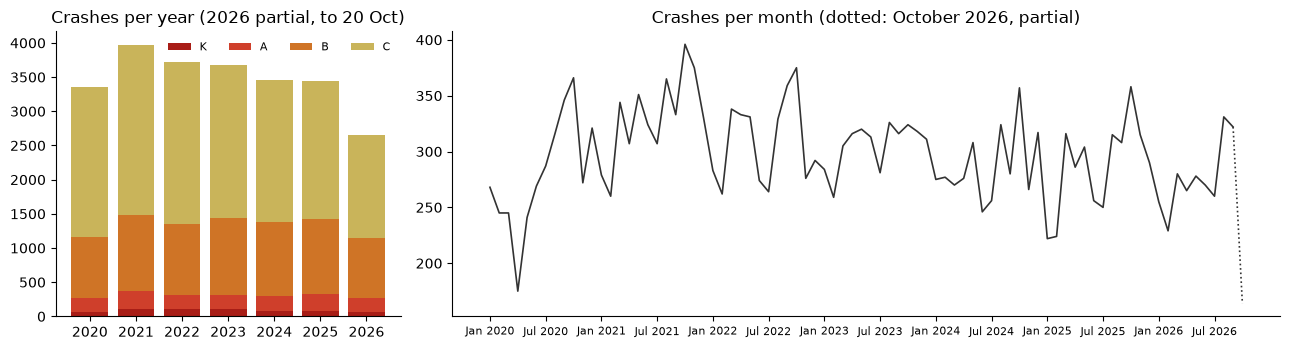

In [15]:
import matplotlib.pyplot as plt

years = pd.DataFrame(metrics.trend(records, "year", data.coverage)["buckets"]).set_index("key")
months = pd.DataFrame(metrics.trend(records, "month", data.coverage)["buckets"])

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.4]})
colors = {"K": "#a81d16", "A": "#cf3f2b", "B": "#cf7426", "C": "#c9b45a"}
bottom = 0
for s in "KABC":                                    # stacked by severity, worst at the bottom
    a.bar(years.index, years[s], bottom=bottom, color=colors[s], label=s)
    bottom = bottom + years[s]
a.set_title("Crashes per year (2026 partial, to 20 Oct)")
a.legend(ncols=4, frameon=False, fontsize=8)
full = months[months["complete"]]
b.plot(full.index, full["crashes"], color="#333", lw=1.2)
b.plot(months.index[-2:], months["crashes"].iloc[-2:], color="#333", lw=1.2, ls=":")  # partial last month
b.set_xticks(range(0, len(months), 6), months["label"][::6], rotation=0, fontsize=8)
b.set_title("Crashes per month (dotted: October 2026, partial)")
for ax in (a, b):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
years[["crashes", "K", "A", "B", "C", "complete"]].T

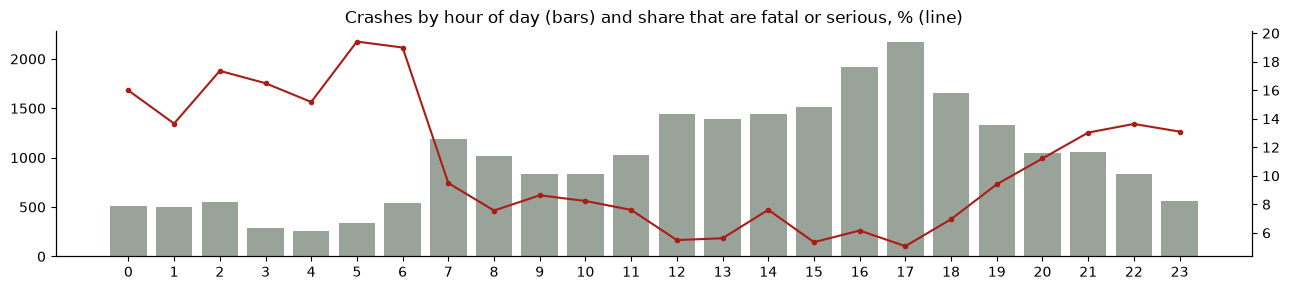

In [16]:
hours = pd.DataFrame(metrics.trend(records, "hour", data.coverage)["buckets"])
hours["ka_share"] = (hours["K"] + hours["A"]) / hours["crashes"]
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(hours["key"], hours["crashes"], color="#9aa39a")
ax2 = ax.twinx()
ax2.plot(hours["key"], hours["ka_share"] * 100, color="#a81d16", marker="o", ms=3)
ax.set_xticks(range(24))
ax.set_title("Crashes by hour of day (bars) and share that are fatal or serious, % (line)")
ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
plt.tight_layout()

## 7. What an analyst should take from this

In [17]:
frame = pd.DataFrame(records)
frame["ka"] = frame["severity"].isin(["K", "A"])
summary = (frame.groupby("rural")["ka"].agg(crashes="size", ka_share="mean")
           .rename(index={False: "urban", True: "rural"}))
by_class = frame.groupby("road_class")["ka"].agg(crashes="size", ka_share="mean").sort_values("ka_share")
summary.round(3), by_class.round(3)

(       crashes  ka_share
 rural                   
 urban    18893     0.048
 rural     5368     0.235,
                      crashes  ka_share
 road_class                            
 NON TRAFFICWAY           782     0.043
 CITY STREET            10677     0.045
 INTERSTATE              1358     0.091
 US & STATE HIGHWAYS     9296     0.113
 OTHER ROADS               21     0.190
 FARM TO MARKET          1406     0.212
 COUNTY ROAD              721     0.248)

* **Volume and severity point to different places.** Lubbock County holds 79 % of the
  district's injury crashes, but only 5.4 % of them are fatal or serious. Rural crashes are
  fewer and almost five times as likely to be K or A (23.5 % vs 4.8 %); county roads and
  farm-to-market roads reach 21–25 %.
* **The monthly series has one clear shock**: April 2020 (stay-at-home orders) is the lowest
  complete month, about 175 crashes against a typical 300. Otherwise the district runs at
  3,400–4,000 injury crashes a year with no steady trend.
* **Night crashes are rarer and worse.** Crashes peak at 15:00–18:00, while the K+A share is
  highest between 21:00 and 06:59 (13–19 %, against 5–10 % from 07:00 to 19:59).
* **Speed and right-of-way dominate the coded factors.** Failing to control speed is cited in
  23 % of crashes, then failing to yield at a stop sign or when turning left. Frequency is not
  severity: *failed to drive in single lane* ranks 4th by count but 18 % of its crashes are K or A,
  against 5 % for *failed to control speed*.

Limits to keep in mind: these are injury crashes only (no O crashes), counts are not rates
(no exposure such as AADT or VMT here), and 2026 is incomplete.